# Podstawy sieci neuronowych - wielowarstwowy perceptron (MLP)

**Plan notatnika:**
1. Od regresji logistycznej do sieci neuronowej
2. Sztuczny neuron
3. Od neuronu do sieci: warstwy i liczba parametrów
4. Po co warstwy ukryte
5. Jak sieć się uczy
6. MLP w scikit-learn na danych rzeczywistych
7. Krzywa straty
8. Hiperparametry MLP
9. Kiedy sieć, a kiedy modele z poprzednich rozdziałów
10. Podsumowanie

**Cele:**
- zrozumieć, że sieć neuronowa składa się z prostych neuronów, które znamy już z regresji logistycznej,
- policzyć liczbę parametrów sieci i wiedzieć, skąd się bierze,
- zobaczyć, kiedy warstwy ukryte pomagają, a kiedy nie,
- wytrenować pierwszy MLP w scikit-learn i porównać go z modelem bazowym i regresją logistyczną.

## 1. Od regresji logistycznej do sieci neuronowej

W rozdziale 3.2 poznaliśmy regresję logistyczną: model liczy **sumę ważoną cech** z wyrazem wolnym, a wynik przepuszcza przez **funkcję sigmoidalną**, która zamienia go na prawdopodobieństwo:

$$p = \sigma(w_1 x_1 + w_2 x_2 + \dots + b)$$

To jest dokładnie **jeden sztuczny neuron** z sigmoidą jako funkcją aktywacji. Sieć neuronowa powstaje, gdy takich neuronów użyjemy **wiele** i połączymy je w warstwy: wyjścia jednych neuronów stają się wejściami następnych.

W tym rozdziale:
- poznamy działanie sieci w scikit-learn (`MLPClassifier`) i sprawdzimy, co dają dodatkowe warstwy,
- w kolejnych notatnikach rozłożymy sieć na części (tensory, aktywacje, funkcje straty, spadek wzdłuż gradientu),
- a potem zbudujemy sieć w bibliotece **Keras**, której używa się w praktyce.

## 2. Sztuczny neuron

Neuron wykonuje trzy kroki:
1. bierze cechy wejściowe $x_i$ i **wagi** $w_i$,
2. liczy **sumę ważoną** i dodaje **bias** (wyraz wolny) $z = \sum_i w_i x_i + b$,
3. przepuszcza wynik przez **funkcję aktywacji** $f$: $a = f(z)$.

![Sztuczny neuron](../obrazki/5.1_perceptron.png)

Wagi i bias to **parametry uczone** w czasie treningu. Wagi mówią, jak ważna jest dana cecha.

Sprawdźmy, że neuron z sigmoidą to faktycznie regresja logistyczna. Wytrenujemy `LogisticRegression` na dwóch cechach i policzymy wynik **ręcznie** ze wzoru neuronu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_circles, make_moons
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_all, y_all = load_breast_cancer(return_X_y=True, as_frame=True)
X2 = StandardScaler().fit_transform(X_all[['mean radius', 'mean texture']])

logreg = LogisticRegression().fit(X2, y_all)

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


In [2]:
w, b = logreg.coef_[0], logreg.intercept_[0]
z = X2 @ w + b                      # suma ważona + bias
a = 1 / (1 + np.exp(-z))            # sigmoida = funkcja aktywacji

print('wagi:', w.round(3), ' bias:', round(b, 3))
print('Czy wynik neuronu = predict_proba?', np.allclose(a, logreg.predict_proba(X2)[:, 1]))

wagi: [-3.336 -0.877]  bias: 0.699
Czy wynik neuronu = predict_proba? True


## 3. Od neuronu do sieci: warstwy i liczba parametrów

**Wielowarstwowy perceptron** (*Multi-Layer Perceptron*, MLP) składa się z:
- **warstwy wejściowej** - po prostu cechy (nie zawiera neuronów, nic się tu nie liczy),
- jednej lub kilku **warstw ukrytych** - neurony uczą się pośrednich wzorców,
- **warstwy wyjściowej** - zwraca predykcję.

![Sieć MLP z dwiema warstwami ukrytymi](../obrazki/5.1_mlp.png)

W warstwie **gęstej** (*dense*, *fully connected*) każdy neuron jest połączony z każdym neuronem poprzedniej warstwy. Jeśli warstwa ma $n_{in}$ wejść i $n_{out}$ neuronów, to ma

$$(n_{in} + 1) \cdot n_{out}$$

parametrów: po jednej wadze na każde połączenie i po jednym biasie na neuron. Dla sieci z rysunku (4 cechy, warstwy ukryte po 5 i 3 neurony, jedno wyjście) daje to $(4+1)\cdot5 + (5+1)\cdot3 + (3+1)\cdot1 = 25 + 18 + 4 = 47$ parametrów.

Uwaga na terminologię: model z jedną warstwą ukrytą to już sieć neuronowa. O **głębokim uczeniu** (*deep learning*) mówimy zwykle wtedy, gdy warstw ukrytych jest więcej (kilka, kilkadziesiąt, a w dużych modelach nawet setki).

## 4. Po co warstwy ukryte

Model liniowy (taki jak regresja logistyczna) potrafi oddzielić klasy tylko **linią prostą** (w wielu wymiarach: hiperpłaszczyzną). Przygotujmy dane, w których klasy tworzą dwa koncentryczne okręgi - żadna prosta ich nie rozdzieli.

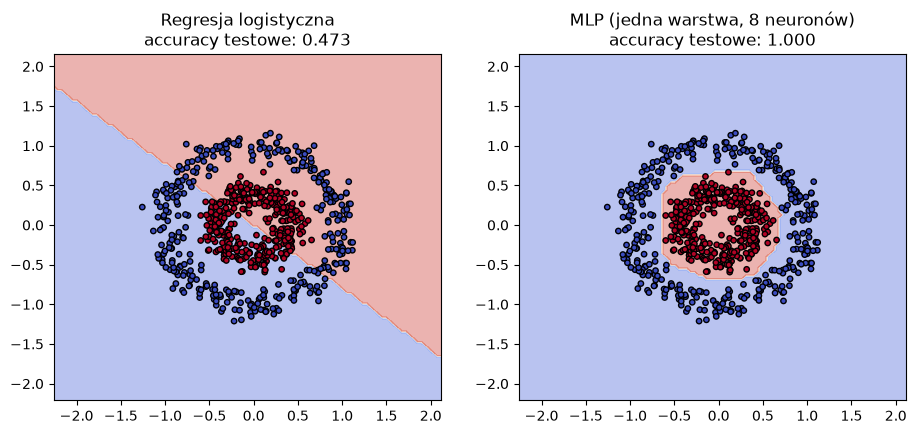

In [3]:
X_c, y_c = make_circles(n_samples=1000, noise=0.1, factor=0.4, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c, test_size=0.3, random_state=42, stratify=y_c
)

lr_c = LogisticRegression().fit(X_train, y_train)
mlp_c = MLPClassifier(hidden_layer_sizes=(8,), max_iter=2000, random_state=42)
mlp_c.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in zip(axes, [lr_c, mlp_c], ['Regresja logistyczna', 'MLP (jedna warstwa, 8 neuronów)']):
    DecisionBoundaryDisplay.from_estimator(
        model, X_train, response_method='predict', cmap='coolwarm', alpha=0.4, ax=ax
    )
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolor='k', s=15)
    ax.set_title(f'{title}\naccuracy testowe: {model.score(X_test, y_test):.3f}')
plt.show()

Regresja logistyczna działa tu jak losowanie (accuracy około 0,5), a MLP z jedną warstwą ukrytą rozdziela klasy niemal bezbłędnie. **Warstwa ukryta z nieliniową funkcją aktywacji** pozwala modelowi „wyginać” granicę decyzyjną.

Policzmy parametry nauczonej sieci. W scikit-learn macierze wag kolejnych warstw są w `coefs_`, a biasy w `intercepts_`.

In [4]:
print('Kształty macierzy wag:', [c.shape for c in mlp_c.coefs_])
print('Kształty biasów:     ', [b.shape for b in mlp_c.intercepts_])

n_params = sum(c.size for c in mlp_c.coefs_) + sum(b.size for b in mlp_c.intercepts_)
print('Liczba parametrów:', n_params)

Kształty macierzy wag: [(2, 8), (8, 1)]
Kształty biasów:      [(8,), (1,)]
Liczba parametrów: 33


Wagi mają kształty $(2, 8)$ i $(8, 1)$, czyli mamy $2\cdot8 + 8\cdot1 = 24$ wagi oraz $8 + 1 = 9$ biasów, razem $(2+1)\cdot8 + (8+1)\cdot1 = 33$ parametry, zgodnie ze wzorem z poprzedniej sekcji.

## 5. Jak sieć się uczy

Uczenie sieci to powtarzanie czterech kroków:
1. **Propagacja w przód** (*forward pass*): dane przechodzą przez kolejne warstwy aż do predykcji.
2. **Liczenie straty** (*loss*): porównujemy predykcję z prawdziwą etykietą.
3. **Propagacja wsteczna** (*backpropagation*): obliczamy, jak zmiana każdej wagi wpłynęłaby na stratę (gradient).
4. **Aktualizacja wag**: optymalizator (np. `adam`) robi krok w stronę mniejszej straty.

Przejście przez cały zbiór treningowy to **epoka**. Sieć zwykle potrzebuje wielu epok. Szczegóły w kolejnych notatnikach.

## 6. MLP w scikit-learn na danych rzeczywistych

Wracamy do zbioru `breast_cancer` z rozdziału 3.2: 569 guzów opisanych 30 cechami. Klasa `1` to guz łagodny, `0` - złośliwy (tak zwraca scikit-learn). Porównamy cztery modele:
- **baseline**: zawsze wskazuje klasę większościową,
- **regresja logistyczna** ze standaryzacją,
- **MLP bez skalowania cech**,
- **MLP ze standaryzacją** (jedna warstwa ukryta, 16 neuronów).

Sieci neuronowe są **wrażliwe na skalę cech**, więc standaryzację umieszczamy w potoku (`make_pipeline`), żeby uczyła się tylko na zbiorze treningowym (rozdział 4.4).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=42, stratify=y_all
)

models = {
    'baseline (klasa większościowa)': DummyClassifier(strategy='most_frequent'),
    'regresja logistyczna': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'MLP bez skalowania': MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=42),
    'MLP ze standaryzacją': make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=42)
    ),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, model.predict(X_test)),
        'ROC AUC': roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,ROC AUC
model,,
baseline (klasa większościowa),0.629,0.500
regresja logistyczna,0.986,0.998
MLP bez skalowania,0.937,0.970
MLP ze standaryzacją,0.972,0.994


Wnioski:
- obie sieci i regresja logistyczna **wyraźnie pokonują model bazowy**,
- **standaryzacja poprawia MLP** - bez niej cechy o dużych wartościach (np. `mean area`) dominują nad pozostałymi i uczenie jest gorsze,
- sieć **nie jest tu lepsza od regresji logistycznej**. Dane są niemal liniowo separowalne, więc dodatkowa elastyczność nic nie daje. Sieci nie są lekiem na wszystko.

## 7. Krzywa straty

Podczas treningu MLP zapamiętuje wartość funkcji straty po każdej epoce w atrybucie `loss_curve_`. Jest to najprostsze narzędzie do sprawdzenia, czy uczenie przebiega prawidłowo.

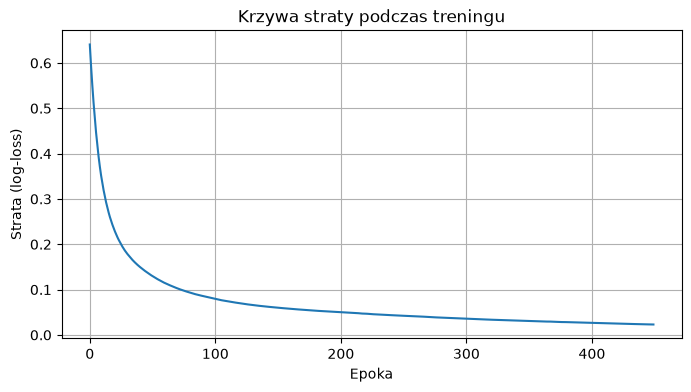

Liczba wykonanych epok: 450


In [5]:
mlp = models['MLP ze standaryzacją'].named_steps['mlpclassifier']

plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_)
plt.title('Krzywa straty podczas treningu')
plt.xlabel('Epoka')
plt.ylabel('Strata (log-loss)')
plt.grid(True)
plt.show()

print('Liczba wykonanych epok:', mlp.n_iter_)

Strata na początku szybko spada, a potem się wypłaszcza - to oznaka poprawnego uczenia. Jeśli strata mocno skacze albo nie maleje, warto zmienić parametry (np. mniejszy `learning_rate_init`, więcej epok).

## 8. Hiperparametry MLP

| Parametr | Znaczenie |
|---|---|
| `hidden_layer_sizes` | liczba neuronów w kolejnych warstwach ukrytych, np. `(32, 16)` |
| `activation` | funkcja aktywacji w warstwach ukrytych (`'relu'`, `'tanh'`, `'logistic'`) |
| `solver` | algorytm optymalizacji (`'adam'`, `'sgd'`, `'lbfgs'`) |
| `alpha` | siła regularyzacji L2 (kara za duże wagi) |
| `learning_rate_init` | początkowa wielkość kroku optymalizatora |
| `max_iter` | maksymalna liczba epok |
| `early_stopping` | zatrzymanie treningu, gdy wynik na walidacji przestaje się poprawiać |

Zobaczmy, jak **liczba neuronów i warstw** wpływa na wynik. Użyjemy zbioru dwóch „księżyców” z dużym szumem i porównamy accuracy treningowe i testowe (rozdział 4.3: niedouczenie i przeuczenie).

In [6]:
X_m, y_m = make_moons(n_samples=1000, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_m, y_m, test_size=0.3, random_state=42, stratify=y_m
)

rows = []
for hidden in [(1,), (2,), (4,), (8,), (32,), (128,), (8, 8), (32, 32)]:
    m = MLPClassifier(hidden_layer_sizes=hidden, max_iter=3000, random_state=42)
    m.fit(X_train, y_train)
    rows.append({
        'warstwy ukryte': str(hidden),
        'accuracy treningowe': m.score(X_train, y_train),
        'accuracy testowe': m.score(X_test, y_test),
    })
pd.DataFrame(rows).set_index('warstwy ukryte').round(3)

,accuracy treningowe,accuracy testowe
warstwy ukryte,,
"(1,)",0.839,0.877
"(2,)",0.833,0.870
"(4,)",0.840,0.877
"(8,)",0.853,0.890
"(32,)",0.909,0.940
"(128,)",0.911,0.930
"(8, 8)",0.916,0.923
"(32, 32)",0.913,0.923


Obserwacje:
- sieć z **1-4 neuronami** ma niskie wyniki zarówno na zbiorze treningowym, jak i testowym - jest zbyt prosta (**niedouczenie**),
- zwiększenie liczby neuronów lub warstw poprawia wynik, ale od pewnego momentu **wynik testowy przestaje rosnąć**: sieć ze 128 neuronami nie jest lepsza od sieci z 32, a druga warstwa ukryta niczego tu nie dodaje,
- na tych danych nie widać przeuczenia (wynik testowy nie jest gorszy od treningowego), bo zbiór jest prosty, a dane zawierają losowy szum, którego żaden model nie przewidzi. Większa sieć to jednak więcej parametrów, dłuższy trening i większe ryzyko przeuczenia przy mniejszej liczbie danych, więc zaczynamy od małych architektur i powiększamy je tylko wtedy, gdy model się niedouczał.

## 9. Kiedy sieć, a kiedy modele z poprzednich rozdziałów

| | Dane tabelaryczne (kolumny liczb i kategorii) | Obrazy, dźwięk, tekst |
|---|---|---|
| Najczęstszy wybór | regresja, **las losowy**, boosting drzew | **sieci neuronowe** (CNN, transformery) |
| Dlaczego | modele drzewiaste dobrze radzą sobie z małymi i średnimi tabelami i nie wymagają skalowania | sieci same uczą się cech z surowych danych (pikseli, próbek) |
| Sieci wymagają | skalowania, dużo strojenia, często więcej danych | dużo danych i mocy obliczeniowej (GPU) |

Dlatego od następnego notatnika sieci poznajemy na **obrazach**, a na danych tabelarycznych (notatnik 05) porównamy je uczciwie z modelami z rozdziałów 3 i 4.

## 10. Podsumowanie

1. **Neuron** to suma ważona cech z biasem przepuszczona przez funkcję aktywacji. Regresja logistyczna to jeden neuron z sigmoidą.
2. **MLP** to warstwy takich neuronów. Warstwa gęsta o $n_{in}$ wejściach i $n_{out}$ neuronach ma $(n_{in}+1)\cdot n_{out}$ parametrów.
3. **Warstwy ukryte z nieliniową aktywacją** pozwalają modelowi uczyć się nieliniowych granic decyzyjnych (koncentryczne okręgi).
4. Sieci wymagają **skalowania cech** (potok ze `StandardScaler`).
5. **Krzywa straty** (`loss_curve_`) pokazuje, czy trening przebiega poprawnie.
6. Większa sieć nie znaczy lepsza: porównuj z modelem bazowym i prostszymi modelami oraz obserwuj różnicę między wynikiem treningowym a testowym.